In [ ]:
# Step 1: Mount Google Drive (only needed if working in Google Colab)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Step 2: Import Libraries
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns

Initial Data Snapshot:
   ï»¿id                          car_name          brand      car_model  \
0      1               Toyota Fielder 2011         Toyota        Fielder   
1      2                  Toyota Noah 2005         Toyota           Noah   
2      3               Toyota LiteAce 2001         Toyota        LiteAce   
3      4  Maruti Suzuki Vitara Brezza 1994  Maruti Suzuki  Vitara Brezza   
4      5          Toyota Starlet good 1992         Toyota        Starlet   

   model_year transmission  body_type fuel_type  engine_capacity  travels  \
0        2016    Automatic     Estate       CNG             1500    45852   
1        2010    Automatic  Hatchback       CNG             1998   219630   
2        2001       Manual        Van       CNG             1800   102000   
3        1994       Manual  Hatchback       CNG             1600   113000   
4        1992    Automatic     Saloon       CNG             1300    15000   

     price accident   registration  review  
0  1200000  

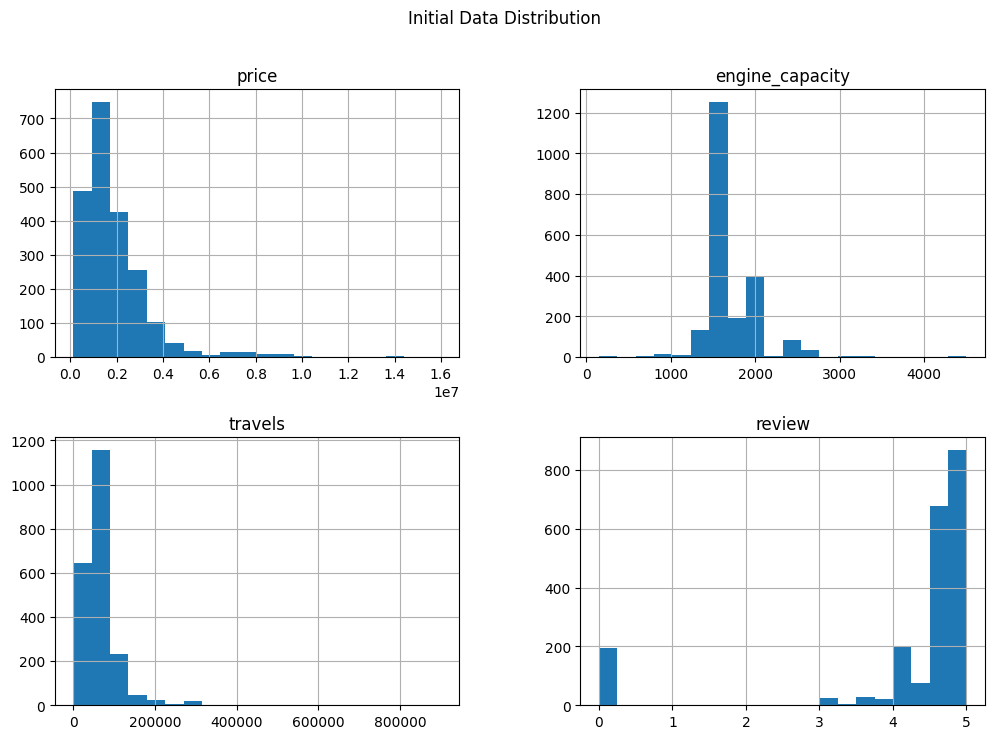

In [ ]:
# Step 3: Load the Dataset
file_path = '/content/drive/MyDrive/Colab Notebooks/dataset_bikroy.csv'
car_df = pd.read_csv(file_path, encoding='latin-1')

# Step 4: Display Initial Data
print("Initial Data Snapshot:")
print(car_df.head())
print("\nData Summary:")
print(car_df.info())

# Plot histogram of initial data for selected columns
car_df[['price', 'engine_capacity', 'travels', 'review']].hist(bins=20, figsize=(12, 8))
plt.suptitle("Initial Data Distribution")
plt.show()

<ipython-input-4-1791680866f5>:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  car_df[col].fillna(car_df[col].mode()[0], inplace=True)
<ipython-input-4-1791680866f5>:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  car_df[col].fillna(car_df[col].mode()[0], inplace=True)
<ipython-input-4-1791680866f5>:12: SettingWithCopyWarning: 
A value is tr

Data Shape after Cleaning: (2093, 14)


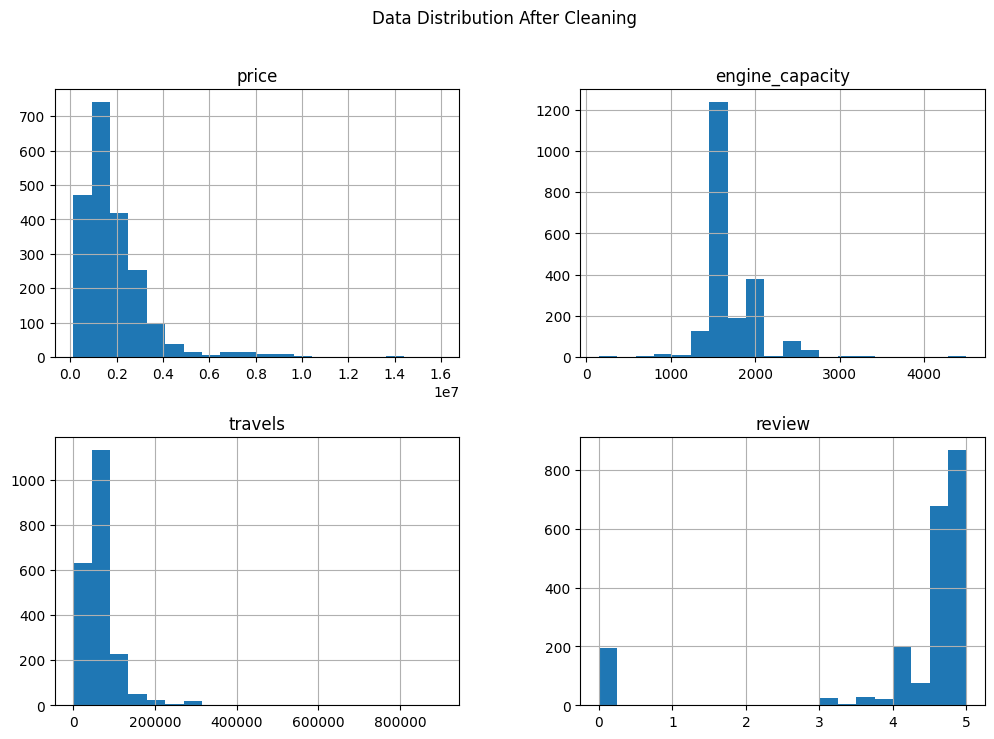

In [ ]:
# Handling Missing Values
car_df.isna().sum()  # Check missing values

# Drop rows with more than 5% missing values
car_df = car_df.dropna(thresh=len(car_df.columns) * 0.95)

# Fill categorical missing values with the most frequent category
for col in ['body_type', 'fuel_type']:
    car_df[col].fillna(car_df[col].mode()[0], inplace=True)

# Check and remove duplicates
car_df.drop_duplicates(keep='first', inplace=True)

# Verify final shape after preprocessing
print("Data Shape after Cleaning:", car_df.shape)

# Plot histogram after cleaning
car_df[['price', 'engine_capacity', 'travels', 'review']].hist(bins=20, figsize=(12, 8))
plt.suptitle("Data Distribution After Cleaning")
plt.show()


Processed Data Snapshot:
   ï»¿id                          car_name fuel_type  engine_capacity  \
0      1               Toyota Fielder 2011       CNG             1500   
1      2                  Toyota Noah 2005       CNG             1998   
2      3               Toyota LiteAce 2001       CNG             1800   
3      4  Maruti Suzuki Vitara Brezza 1994       CNG             1600   
4      5          Toyota Starlet good 1992       CNG             1300   

   travels    price  review  age age_category price_category  \
0    45852  1200000     4.8    8          Old         Medium   
1   219630  1200000     4.8   14     Very Old         Medium   
2   102000   165000     4.9   23     Very Old            Low   
3   113000   230000     0.0   30     Very Old            Low   
4    15000   330000     4.2   32     Very Old            Low   

  engine_capacity_category travels_category review_category  
0                   Medium              Low            Good  
1                     High 

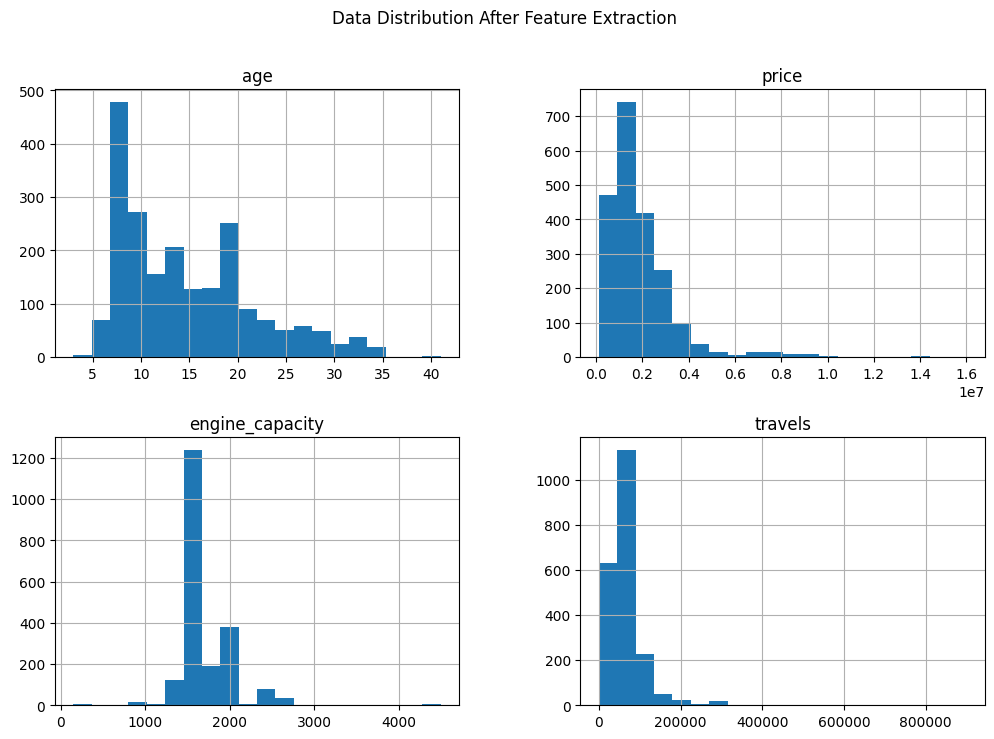

In [ ]:
from datetime import datetime

# Current year for calculating car age
current_year = datetime.now().year

# Feature Extraction Function
def preprocess_and_extract_features(df):
    # Calculate car age
    df['age'] = current_year - df['model_year']

    # Add Age Category
    age_bins = [0, 2, 5, 10, float('inf')]
    age_labels = ['New', 'Recent', 'Old', 'Very Old']
    df['age_category'] = pd.cut(df['age'], bins=age_bins, labels=age_labels)

    # Add Price Category
    price_bins = [0, df['price'].quantile(0.33), df['price'].quantile(0.66), df['price'].max()]
    df['price_category'] = pd.cut(df['price'], bins=price_bins, labels=['Low', 'Medium', 'High'])

    # Add Engine Capacity Category
    engine_bins = [0, 1499, 1799, float('inf')]
    df['engine_capacity_category'] = pd.cut(df['engine_capacity'], bins=engine_bins, labels=['Low', 'Medium', 'High'])

    # Add Travels Category
    travels_bins = [-1, 50000, 150000, float('inf')]
    travels_labels = ['Low', 'Medium', 'High']
    df['travels_category'] = pd.cut(df['travels'], bins=travels_bins, labels=travels_labels)

    # Add Review Category
    rating_bins = [-1, 2, 4, 5]
    rating_labels = ['Poor', 'Average', 'Good']
    df['review_category'] = pd.cut(df['review'], bins=rating_bins, labels=rating_labels)

    # Drop columns not needed after extraction
    df = df.drop(columns=['transmission', 'body_type', 'brand', 'car_model', 'model_year', 'accident ', 'registration'])

    return df

# Apply Feature Extraction
processed_df = preprocess_and_extract_features(car_df)
print("Processed Data Snapshot:")
print(processed_df.head())

# Plot histogram after feature extraction
processed_df[['age', 'price', 'engine_capacity', 'travels']].hist(bins=20, figsize=(12, 8))
plt.suptitle("Data Distribution After Feature Extraction")
plt.show()

In [ ]:
# Combine Features for TF-IDF Vectorization
processed_df['combined_features'] = processed_df['car_name'] + ' ' + \
                                    processed_df['price_category'].astype(str) + ' ' + \
                                    processed_df['engine_capacity_category'].astype(str) + ' ' + \
                                    processed_df['travels_category'].astype(str) + ' ' + \
                                    processed_df['review_category'].astype(str)

# TF-IDF Vectorizer
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(processed_df['combined_features'])

# Compute Cosine Similarity
similarity_matrix = cosine_similarity(tfidf_matrix)
print("Cosine Similarity Matrix Shape:", similarity_matrix.shape)

Cosine Similarity Matrix Shape: (2093, 2093)


Enter your preferred maximum price: 2000000
Enter preferred maximum age of the car: 20
Enter maximum kilometers traveled: 60000
Enter preferred minimum engine capacity (cc): 1500
Average Similarity Score (Accuracy): 29.57%


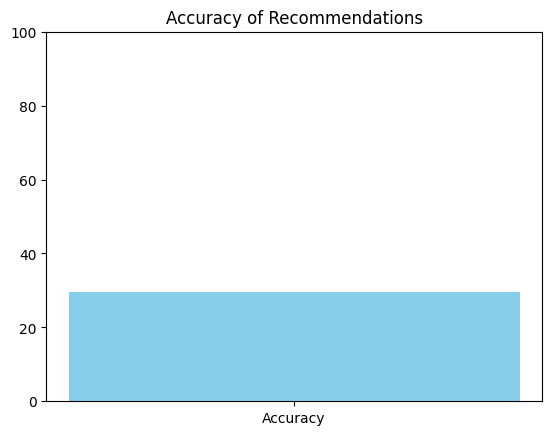

Recommendations Based on Buyer Preferences:
                     car_name    price  engine_capacity  age review_category
1007  Toyota Axio HYBRID 2016  1829995             1500    8            Good
1008  Toyota Axio HYBRID 2016  1829995             1500    8            Good
8     Toyota Axio HYBRID 2016  1830000             1500    8            Good
895   Toyota Axio Hybrid 2016  1850000             1500    8            Good
9     Toyota Axio HYBRID 2016  1830000             1500    8            Good


In [ ]:
# Function to Get Buyer Preferences
def get_buyer_preferences():
    price = int(input("Enter your preferred maximum price: "))
    age = int(input("Enter preferred maximum age of the car: "))
    travels = int(input("Enter maximum kilometers traveled: "))
    engine_capacity = int(input("Enter preferred minimum engine capacity (cc): "))

    return {'price': price, 'age': age, 'travels': travels, 'engine_capacity': engine_capacity}

# Recommendation Function
def recommend_cars(df, similarity_matrix, buyer_preferences, top_n=5):
    filtered_cars = df[(df['price'] <= buyer_preferences['price']) &
                       (df['age'] <= buyer_preferences['age']) &
                       (df['travels'] <= buyer_preferences['travels']) &
                       (df['engine_capacity'] >= buyer_preferences['engine_capacity'])]

    # Find indices of filtered cars
    filtered_indices = filtered_cars.index
    avg_similarity_scores = similarity_matrix[filtered_indices].mean(axis=0)

    # Sort by similarity
    similar_cars_indices = avg_similarity_scores.argsort()[::-1][:top_n]
    recommended_cars = df.iloc[similar_cars_indices]

    # Calculate accuracy based on average similarity score
    avg_similarity_score = avg_similarity_scores[similar_cars_indices].mean()
    accuracy = avg_similarity_score * 100
    print(f"Average Similarity Score (Accuracy): {accuracy:.2f}%")

    # Plot accuracy
    plt.figure()
    plt.bar(["Accuracy"], [accuracy], color='skyblue')
    plt.ylim(0, 100)
    plt.title("Accuracy of Recommendations")
    plt.show()

    return recommended_cars[[ 'car_name', 'price', 'engine_capacity', 'age', 'review_category']]

# Get Buyer Preferences and Generate Recommendations
buyer_preferences = get_buyer_preferences()
recommendations = recommend_cars(processed_df, similarity_matrix, buyer_preferences)
print("Recommendations Based on Buyer Preferences:")
print(recommendations)













Enter a car name or part of a car name: axio
Using car: Toyota Axio HYBRID 2016 for recommendations.
Average Similarity Score (Accuracy): 20.43%


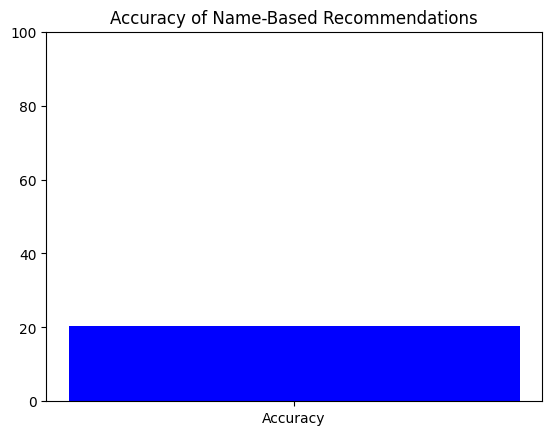

Recommendations Based on Car Name:
                                       car_name    price  engine_capacity  \
8                       Toyota Axio HYBRID 2016  1830000             1500   
9                       Toyota Axio HYBRID 2016  1830000             1500   
895                     Toyota Axio Hybrid 2016  1850000             1500   
1007                    Toyota Axio HYBRID 2016  1829995             1500   
1008                    Toyota Axio HYBRID 2016  1829995             1500   
...                                         ...      ...              ...   
1876  Land Rover Discovery EUROPEAN BEAUTY 2017  7500000             2000   
2081                 Honda CR-V Over Fresh 2012  2950000             2000   
2082                 Honda CR-V Over Fresh 2012  2950000             2000   
2115                   Nissan X-Trail 20.X 2017  4000000             2000   
2116                   Nissan X-Trail 20.X 2017  4000000             2000   

      age review_category  
8       8   

In [ ]:
# Function for Recommendations Based on Partial Car Name
def get_recommendations_by_partial_name(car_name_partial, cosine_sim=similarity_matrix, num_recommendations=5):
    # Find cars that match the partial name
    matches = car_df[car_df['car_name'].str.contains(car_name_partial, case=False)]

    if matches.empty:
        print("No car found matching the given name. Please try a different name.")
        return None, None

    # Use the first matching car for similarity
    idx = matches.index[0]
    print(f"Using car: {matches.iloc[0]['car_name']} for recommendations.")

    # Get similarity scores and sort
    # similarity measure
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    # Get top recommended cars
    car_indices = [i[0] for i in sim_scores]

    # Calculate accuracy based on similarity scores
    avg_similarity_score = np.mean([score for _, score in sim_scores]) * 100
    print(f"Average Similarity Score (Accuracy): {avg_similarity_score:.2f}%")

    # Plot accuracy
    plt.figure()
    plt.bar(["Accuracy"], [avg_similarity_score], color='blue')
    plt.ylim(0, 100)
    plt.title("Accuracy of Name-Based Recommendations")
    plt.show()

    # Display recommendations
    recommended_cars = car_df.iloc[car_indices]
    return recommended_cars[[ 'car_name', 'price', 'engine_capacity', 'age', 'review_category']]

# Buyer Input for Partial Car Name
car_name_partial = input("Enter a car name or part of a car name: ")
recommended_cars = get_recommendations_by_partial_name(car_name_partial)

# Display recommendations if available
if recommended_cars is not None:
    print("Recommendations Based on Car Name:")
    print(recommended_cars)